In [27]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import numpy as np

In [28]:
torch.cuda.is_available()
df = pd.read_csv("test_train.csv")

features = ['x', 'y', 'z', 'vx', 'vy', 'vz', 'days_offset']
targets = ['x_error', 'y_error', 'z_error']

X = df[features].values
y = df[targets].values

#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
split_idx = int(len(df) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

df_test = df.iloc[split_idx:].reset_index(drop=True)

scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train = scaler_y.fit_transform(y_train)
y_test = scaler_y.transform(y_test)

# X_tensor = torch.tensor(X, dtype=torch.float32)
# y_tensor = torch.tensor(y, dtype=torch.float32)
# dataset = TensorDataset(X_tensor, y_tensor)

train_dataset = TensorDataset(  
    torch.tensor(X_train, dtype=torch.float32), 
    torch.tensor(y_train, dtype=torch.float32)
)
test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32), 
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)


In [29]:
class Model(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(7, 128),
            nn.GELU(),
            nn.Linear(128, 128),
            nn.GELU(),
            nn.Linear(128,128),
            nn.ReLU(),
            nn.Linear(128, 3)
        )

    def forward(self, x):
        return self.network(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Model().to(device=device)

loss_fn = nn.L1Loss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

epochs = 1000
for epoch in range(epochs):
    model.train()
    ov_loss = 0.0

    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        y_pred = model(batch_X)
        loss = loss_fn(y_pred, batch_y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        ov_loss += loss.item() * batch_X.size(0)

    epoch_loss = ov_loss / len(train_dataset)

    if (epoch + 1) % 100 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss:.4f}")

Epoch [100/1000], Loss: 0.0243
Epoch [200/1000], Loss: 0.0120
Epoch [300/1000], Loss: 0.0103
Epoch [400/1000], Loss: 0.0182
Epoch [500/1000], Loss: 0.0105
Epoch [600/1000], Loss: 0.0075
Epoch [700/1000], Loss: 0.0078
Epoch [800/1000], Loss: 0.0071
Epoch [900/1000], Loss: 0.0079
Epoch [1000/1000], Loss: 0.0076


In [30]:
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        y_pred = model(batch_X)
        all_preds.append(y_pred.cpu().numpy())
        all_targets.append(batch_y.cpu().numpy())

preds_array = np.vstack(all_preds)
targets_array = np.vstack(all_targets)

preds_km = scaler_y.inverse_transform(preds_array)
targets_km = scaler_y.inverse_transform(targets_array)

err3d_model = np.linalg.norm(preds_km - targets_km, axis=1)
err3d_raw_sgp4 = np.linalg.norm(targets_km, axis=1)

df_test['Err3D_Model'] = err3d_model
df_test['Err3D_SGP4'] = err3d_raw_sgp4

print("\n=== PODSUMOWANIE OGÓLNE 3D [km] ===")
print(f"SGP4  -> Średnia: {err3d_raw_sgp4.mean():.3f} | Mediana: {np.median(err3d_raw_sgp4):.3f} | 90th perc (ogon): {np.percentile(err3d_raw_sgp4, 90):.3f}")
print(f"Model -> Średnia: {err3d_model.mean():.3f} | Mediana: {np.median(err3d_model):.3f} | 90th perc (ogon): {np.percentile(err3d_model, 90):.3f}")

print("\n=== BŁĄD 3D W ROZBICIU NA DAYS_OFFSET [km] ===")
summary = df_test.groupby('days_offset').apply(lambda g: pd.Series({
    'Liczba_Próbek': len(g),
    'Mediana_SGP4': g['Err3D_SGP4'].median(),
    'Mediana_Model': g['Err3D_Model'].median(),
    'Średnia_SGP4': g['Err3D_SGP4'].mean(),
    'Średnia_Model': g['Err3D_Model'].mean(),
    '90perc_SGP4': np.percentile(g['Err3D_SGP4'], 90),
    '90perc_Model': np.percentile(g['Err3D_Model'], 90)
}))

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(summary.round(3).to_string())


=== PODSUMOWANIE OGÓLNE 3D [km] ===
SGP4  -> Średnia: 4.084 | Mediana: 2.485 | 90th perc (ogon): 10.219
Model -> Średnia: 4.329 | Mediana: 2.728 | 90th perc (ogon): 10.531

=== BŁĄD 3D W ROZBICIU NA DAYS_OFFSET [km] ===
             Liczba_Próbek  Mediana_SGP4  Mediana_Model  Średnia_SGP4  Średnia_Model  90perc_SGP4  90perc_Model
days_offset                                                                                                    
0                    105.0         1.271          1.771         1.420          1.812        2.484         2.633
1                    105.0         1.155          1.763         1.317          1.781        2.485         2.753
2                    106.0         1.085          1.614         1.244          1.733        2.122         2.846
3                    106.0         1.315          1.663         1.389          1.863        2.119         3.283
4                    106.0         1.958          2.178         1.920          2.280        2.943         3

C:\Users\kozak\AppData\Local\Temp\ipykernel_12592\2958093815.py:29: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = df_test.groupby('days_offset').apply(lambda g: pd.Series({


In [31]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

# Szybki test na obecnych danych
X_train, X_test, y_train, y_test = train_test_split(X, y[:, 0], test_size=0.2, shuffle=False) # Chronologicznie!

gbr = GradientBoostingRegressor(n_estimators=100, random_state=42)
gbr.fit(X_train, y_train)
preds = gbr.predict(X_test)

print("MAE Gradient Boosting dla osi X:", mean_absolute_error(y_test, preds))

MAE Gradient Boosting dla osi X: 7.774886771367576


In [32]:
N = 10  # ile ostatnich wierszy pokazać

view = pd.DataFrame({
    'target_epoch':  df_test['target_epoch'].values,
    'days_offset':   df_test['days_offset'].values,

    # prawdziwy błąd SGP4 (prawda_SP3 - SGP4), bez korekty
    'SGP4_dx': targets_km[:, 0],
    'SGP4_dy': targets_km[:, 1],
    'SGP4_dz': targets_km[:, 2],

    # korekta przewidziana przez model
    'Model_dx': preds_km[:, 0],
    'Model_dy': preds_km[:, 1],
    'Model_dz': preds_km[:, 2],

    # odległość od prawdy w 3D: bez korekty vs z korektą
    'Dist_SGP4 [km]':  np.linalg.norm(targets_km, axis=1),
    'Dist_Model [km]': np.linalg.norm(targets_km - preds_km, axis=1),
})
view['Poprawa [km]'] = view['Dist_SGP4 [km]'] - view['Dist_Model [km]']  # >0 = model pomógł

pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)
print(view.tail(N).round(3).to_string(index=False))

       target_epoch  days_offset  SGP4_dx  SGP4_dy  SGP4_dz  Model_dx  Model_dy  Model_dz  Dist_SGP4 [km]  Dist_Model [km]  Poprawa [km]
2025-11-09 12:00:00            1    1.267    0.435   -0.463    -0.584    -0.080    -0.066           1.417            1.962        -0.545
2025-11-10 12:00:00            2    0.989    0.367    0.383     0.500     0.156    -0.128           1.122            0.738         0.384
2025-11-11 12:00:00            3    0.075    0.148    1.317     1.113     0.323    -0.568           1.327            2.158        -0.831
2025-11-12 12:00:00            4   -1.291   -0.198    2.369     1.685     0.396    -1.150           2.705            4.647        -1.942
2025-11-13 12:00:00            5   -2.916   -0.602    3.553     1.549     0.207    -1.160           4.636            6.542        -1.906
2025-11-14 12:00:00            6   -4.667   -0.996    4.852     1.152    -0.008    -0.564           6.805            8.011        -1.205
2025-11-15 12:00:00            7   -6.472

In [33]:
view = pd.DataFrame({
    'tle_epoch':   df_test['tle_epoch'].values,
    'target_epoch': df_test['target_epoch'].values,
    'days_offset': df_test['days_offset'].values,

    # surowy wynik SGP4 (pozycja, km)
    'SGP4_x': df_test['x'].values,
    'SGP4_y': df_test['y'].values,
    'SGP4_z': df_test['z'].values,

    # surowy wynik modelu (przewidziany błąd, km)
    'Model_x': preds_km[:, 0],
    'Model_y': preds_km[:, 1],
    'Model_z': preds_km[:, 2],
})
print(view.tail(10).round(3).to_string(index=False))

                 tle_epoch        target_epoch  days_offset     SGP4_x    SGP4_y     SGP4_z  Model_x  Model_y  Model_z
2025-11-08 21:41:41.776800 2025-11-09 12:00:00            1 -21362.791 21558.166 -29270.854   -0.584   -0.080   -0.066
2025-11-08 21:41:41.776800 2025-11-10 12:00:00            2 -21558.905 21818.017 -28935.159    0.500    0.156   -0.128
2025-11-08 21:41:41.776800 2025-11-11 12:00:00            3 -21747.065 22085.347 -28592.119    1.113    0.323   -0.568
2025-11-08 21:41:41.776800 2025-11-12 12:00:00            4 -21926.749 22359.631 -28242.227    1.685    0.396   -1.150
2025-11-08 21:41:41.776800 2025-11-13 12:00:00            5 -22097.327 22640.501 -27885.970    1.549    0.207   -1.160
2025-11-08 21:41:41.776800 2025-11-14 12:00:00            6 -22258.175 22927.725 -27523.751    1.152   -0.008   -0.564
2025-11-08 21:41:41.776800 2025-11-15 12:00:00            7 -22408.758 23221.172 -27155.845    0.455   -0.269    0.519
2025-11-08 21:41:41.776800 2025-11-16 12:00:00  

In [34]:
for a in [0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]:
    e = np.linalg.norm(targets_km - a * preds_km, axis=1)
    print(a, e.mean().round(3), np.median(e).round(3), np.percentile(e, 90).round(3))

0 4.084 2.485 10.219
0.25 3.796 2.285 9.531
0.5 3.714 2.209 9.358
0.75 3.897 2.333 9.509
1.0 4.329 2.728 10.531
1.5 5.607 3.684 13.273
2.0 7.153 4.686 16.628


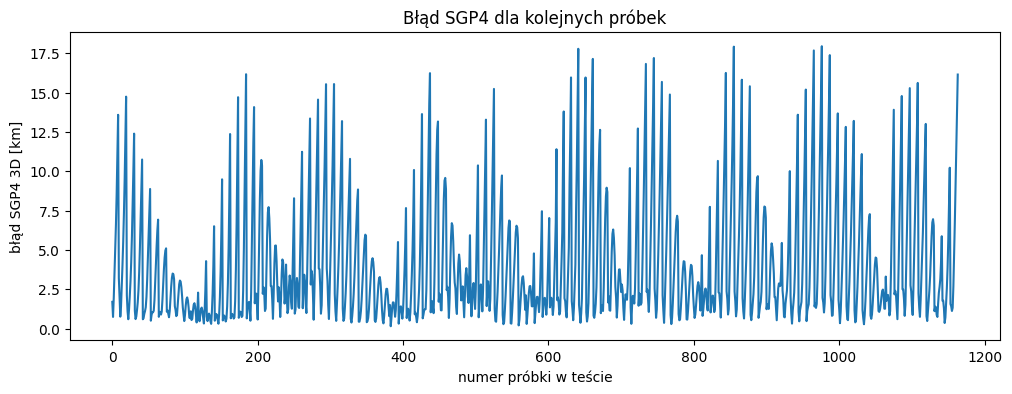

                            max_err  err_offset0   n
tle_epoch                                           
2025-10-21 16:06:54.233856      3.3          1.1  11
2025-10-25 19:00:24.773760     13.9          1.8  11
2025-10-26 16:52:38.552736     14.8          2.2  11
2025-10-27 18:57:57.556800     15.3          2.5  11
2025-10-28 14:40:51.164256     15.6          2.8  11
2025-10-30 17:58:11.332128     13.0          2.2  11
2025-11-01 16:19:44.842368      7.0          0.8  11
2025-11-03 15:51:02.817792      5.9          1.1  11
2025-11-04 20:48:13.386240     10.2          1.8  11
2025-11-08 21:41:41.776800     16.1          1.6  11


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

err = np.linalg.norm(targets_km, axis=1)   # błąd SGP4 w km, jedna wartość na próbkę
plt.figure(figsize=(12, 4))
plt.plot(err)
plt.xlabel('numer próbki w teście')
plt.ylabel('błąd SGP4 3D [km]')
plt.title('Błąd SGP4 dla kolejnych próbek')
plt.show()



d = df_test.copy()
d['err'] = err
per_tle = d.groupby('tle_epoch').agg(
    max_err=('err', 'max'),
    err_offset0=('err', 'first'),
    n=('err', 'size')
).sort_values('tle_epoch')
print(per_tle.tail(10).round(1))

In [36]:
age = df_test['days_offset'].values
use = age >= 5
err_hybrid = np.where(use, err3d_model, err3d_raw_sgp4)
print("SGP4  :", err3d_raw_sgp4.mean().round(3), np.median(err3d_raw_sgp4).round(3), np.percentile(err3d_raw_sgp4, 90).round(3))
print("hybryda:", err_hybrid.mean().round(3), np.median(err_hybrid).round(3), np.percentile(err_hybrid, 90).round(3))

for a in [0, 0.25, 0.5, 0.75, 1.0]:
    e = np.linalg.norm(targets_km[use] - a * preds_km[use], axis=1)
    print(a, e.mean().round(3), np.median(e).round(3), np.percentile(e, 90).round(3))

SGP4  : 4.084 2.485 10.219
hybryda: 4.131 2.449 10.531
0 6.263 5.273 12.634
0.25 5.752 4.649 11.914
0.5 5.535 4.342 11.528
0.75 5.739 4.577 12.085
1.0 6.351 5.002 13.455
